In [1]:
%%writefile ../src/plants.py
import numpy as np

def simulate(Kp, Ki, Kd, setpoint=10.0, t_end=3.0, K=1.0, tau=0.5, dt=0.01,
             umax=12.0, dz=1.5, fric=0.5, q=0.05, noise=0.02, delay=True,
             antiwindup=False, d_tau=0.0, seed=0):
    """Closed-loop simulation of a motor with real-world effects.
    Set umax=np.inf, dz=0, fric=0, q=0, noise=0, delay=False to switch effects off.
    antiwindup=True stops the integral growing while the output is saturated.
    d_tau is the derivative filter time constant in seconds (0 = no filter)."""
    rng = np.random.default_rng(seed)
    n = int(t_end / dt)
    t = np.arange(n) * dt
    y = np.zeros(n)
    u_log = np.zeros(n)
    omega = 0.0
    integral = 0.0
    prev_e = 0.0
    d_filt = 0.0
    u_prev = 0.0
    alpha = d_tau / (d_tau + dt)          # 0 means no filtering

    for k in range(n):
        # sensor: noise, then quantization
        meas = omega + (rng.normal(0, noise) if noise > 0 else 0.0)
        if q > 0:
            meas = np.round(meas / q) * q

        # discrete PID
        e = setpoint - meas
        d_raw = 0.0 if k == 0 else (e - prev_e) / dt
        prev_e = e
        d_filt = alpha * d_filt + (1 - alpha) * d_raw     # low-pass filter on D

        integral_new = integral + e * dt
        u_raw = Kp * e + Ki * integral_new + Kd * d_filt
        u = np.clip(u_raw, -umax, umax)                    # saturation

        # clamping: skip the integral update if clipped AND error pushes deeper
        pushing_deeper = (u != u_raw) and (np.sign(e) == np.sign(u_raw))
        if not (antiwindup and pushing_deeper):
            integral = integral_new
        u_log[k] = u

        # one-sample delay
        u_apply = u_prev if delay else u
        u_prev = u

        # deadband and friction
        if abs(u_apply) < dz:
            u_eff = 0.0
        else:
            u_eff = u_apply - fric * np.sign(u_apply)

        # motor dynamics: 10 Euler sub-steps per sample
        for _ in range(10):
            omega += (-omega + K * u_eff) / tau * (dt / 10)
        y[k] = omega

    return t, y, u_log

Overwriting ../src/plants.py


In [2]:
%matplotlib inline
import sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.append("../src")
from metrics import step_metrics
from plants import simulate

off = dict(umax=np.inf, dz=0, fric=0, q=0, noise=0, delay=False)

In [3]:
t, y, u = simulate(5, 10, 0, **{**off, "umax": 12.0})
m = step_metrics(t, y / 10)
print(f"OS={m['overshoot']:.1f}%  settle={m['settling_time']:.2f}s  final={y[-1]:.2f}")

OS=14.5%  settle=2.70s  final=10.26


Ki=10  no anti-windup  OS= 14.5%  settle=2.70s  final=10.26
Ki=10  clamping        OS=  0.0%  settle=1.60s  final=9.99
Ki=50  no anti-windup  OS= 15.4%  settle=2.97s  final=10.36
Ki=50  clamping        OS=  0.8%  settle=0.86s  final=10.00


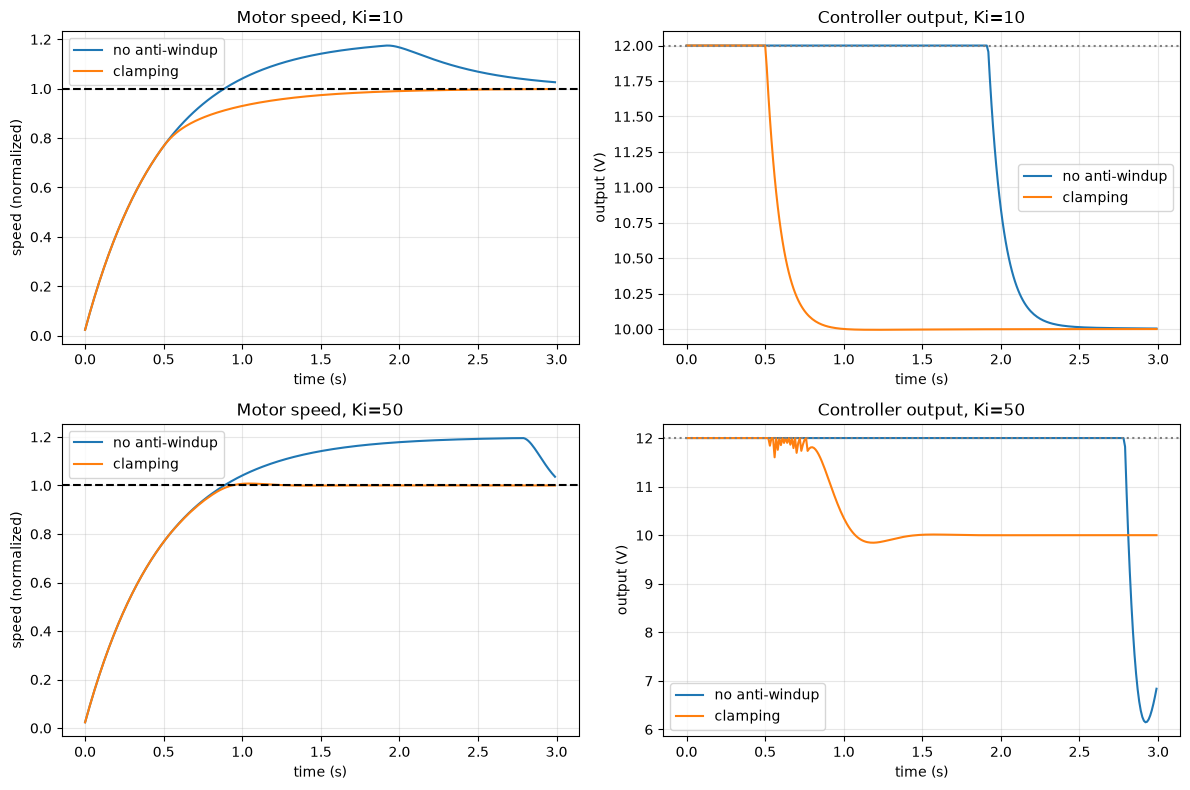

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, Ki in enumerate([10, 50]):
    for name, aw in {"no anti-windup": False, "clamping": True}.items():
        t, y, u = simulate(5, Ki, 0, **{**off, "umax": 12.0}, antiwindup=aw)
        m = step_metrics(t, y / 10)
        print(f"Ki={Ki:<3} {name:15} OS={m['overshoot']:5.1f}%  "
              f"settle={m['settling_time']:.2f}s  final={y[-1]:.2f}")
        axes[row, 0].plot(t, y / 10, label=name)
        axes[row, 1].plot(t, u, label=name)
    axes[row, 0].axhline(1, ls="--", color="k")
    axes[row, 0].set_title(f"Motor speed, Ki={Ki}")
    axes[row, 0].set_ylabel("speed (normalized)")
    axes[row, 1].axhline(12, ls=":", color="gray")
    axes[row, 1].set_title(f"Controller output, Ki={Ki}")
    axes[row, 1].set_ylabel("output (V)")
    for ax in axes[row]:
        ax.set_xlabel("time (s)"); ax.grid(True, alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig("../plots/antiwindup.png", dpi=150); plt.show()

no filter      output jitter (std after 1 s) = 16.43
filter 0.05 s  output jitter (std after 1 s) = 2.26


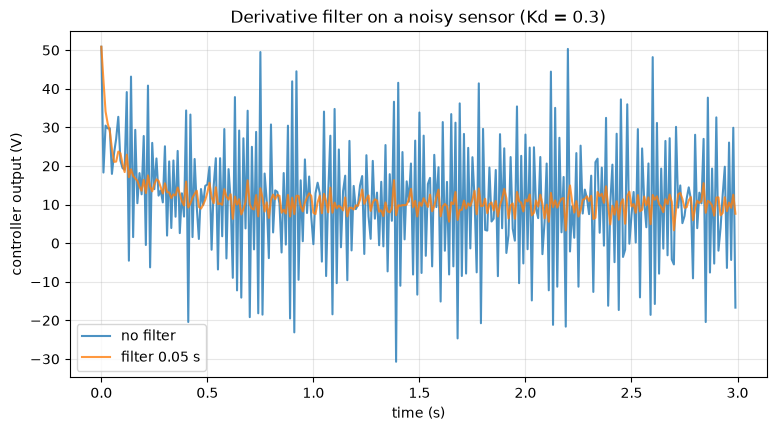

In [5]:
plt.figure(figsize=(9, 4.5))
for name, d_tau in {"no filter": 0.0, "filter 0.05 s": 0.05}.items():
    t, y, u = simulate(5, 10, 0.3, **{**off, "noise": 0.2}, d_tau=d_tau)
    print(f"{name:14} output jitter (std after 1 s) = {np.std(u[100:]):.2f}")
    plt.plot(t, u, label=name, alpha=0.8)
plt.xlabel("time (s)"); plt.ylabel("controller output (V)")
plt.title("Derivative filter on a noisy sensor (Kd = 0.3)")
plt.legend(); plt.grid(True, alpha=0.3)
plt.savefig("../plots/derivative_filter.png", dpi=150); plt.show()